In [1]:
import os, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
REPO = "India-Demand-Forecasting-ML"
BRANCH = "feature/cleaning-weather-eda"
if not os.path.exists(REPO):
    !git clone -b {BRANCH} https://github.com/tanishmaity03/India-Demand-Forecasting-ML.git
%cd {REPO}

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)
Path("results/figures").mkdir(parents=True, exist_ok=True); Path("results/tables").mkdir(parents=True, exist_ok=True)

REGIONS = ["northern", "western", "eastern", "southern", "north_eastern"]
df = pd.read_csv("data/processed/india_demand_weather.csv", parse_dates=["datetime"])
df["hour"] = df["datetime"].dt.hour; df["month"] = df["datetime"].dt.month
df["year"] = df["datetime"].dt.year; df["dow"] = df["datetime"].dt.dayofweek
print(df.shape)

Cloning into 'India-Demand-Forecasting-ML'...
remote: Enumerating objects: 72, done.
remote: Counting objects: 100% (72/72), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 72 (delta 16), reused 63 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (72/72), 18.51 MiB | 17.91 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/India-Demand-Forecasting-ML
(46728, 24)


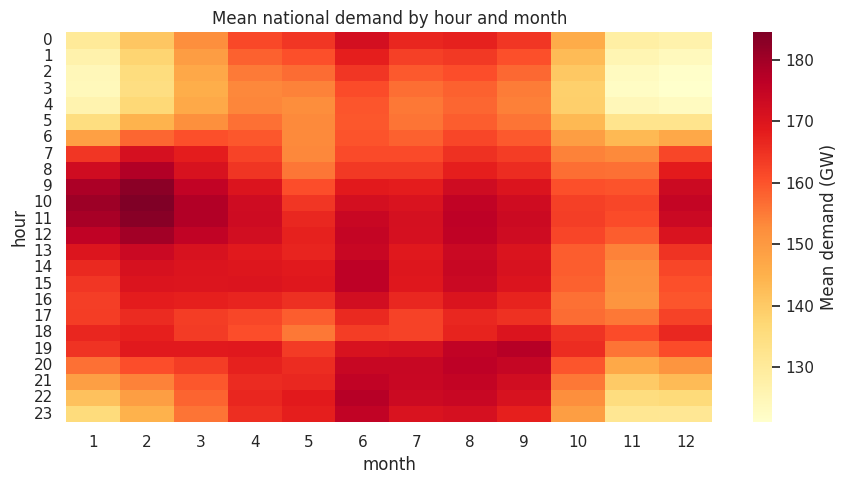

In [2]:
piv = df.pivot_table(index="hour", columns="month", values="national", aggfunc="mean") / 1000
plt.figure(figsize=(9, 5))
sns.heatmap(piv, cmap="YlOrRd", cbar_kws={"label": "Mean demand (GW)"})
plt.title("Mean national demand by hour and month"); plt.tight_layout()
plt.savefig("results/figures/03_heatmap_hour_month.png", dpi=150); plt.show()

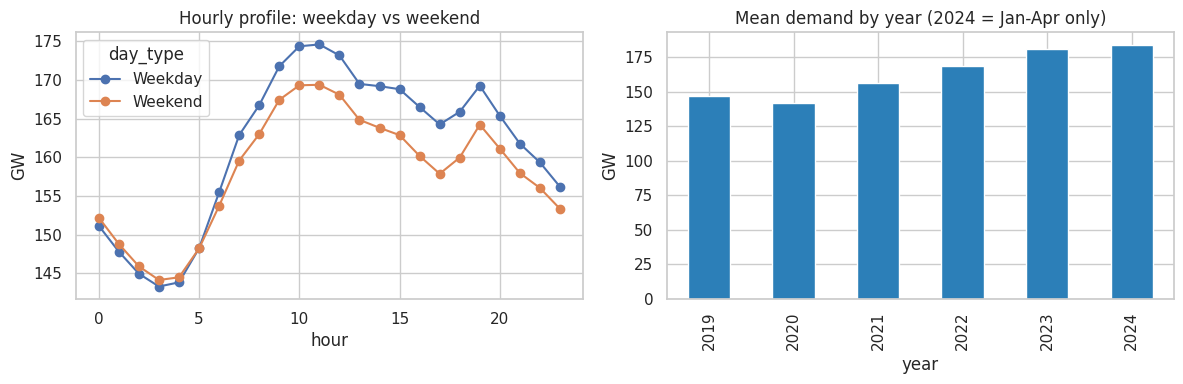

{2019: 146.8, 2020: 142.0, 2021: 156.3, 2022: 168.9, 2023: 180.8, 2024: 183.8}


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(df.assign(day_type=np.where(df["dow"] >= 5, "Weekend", "Weekday"))
   .groupby(["hour", "day_type"])["national"].mean().div(1000).unstack()
   .plot(ax=axes[0], marker="o"))
axes[0].set_title("Hourly profile: weekday vs weekend"); axes[0].set_ylabel("GW")
yearly = df.groupby("year")["national"].mean().div(1000)
yearly.plot.bar(ax=axes[1], color="#2c7fb8")
axes[1].set_title("Mean demand by year (2024 = Jan-Apr only)"); axes[1].set_ylabel("GW")
plt.tight_layout(); plt.savefig("results/figures/03_weekday_weekend_yearly.png", dpi=150); plt.show()
print(yearly.round(1).to_dict())

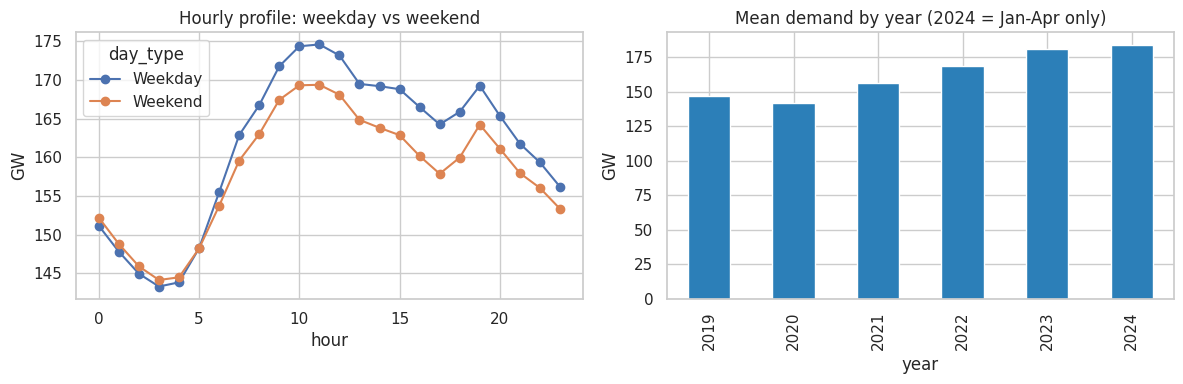

{2019: 146.8, 2020: 142.0, 2021: 156.3, 2022: 168.9, 2023: 180.8, 2024: 183.8}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(df.assign(day_type=np.where(df["dow"] >= 5, "Weekend", "Weekday"))
   .groupby(["hour", "day_type"])["national"].mean().div(1000).unstack()
   .plot(ax=axes[0], marker="o"))
axes[0].set_title("Hourly profile: weekday vs weekend"); axes[0].set_ylabel("GW")
yearly = df.groupby("year")["national"].mean().div(1000)
yearly.plot.bar(ax=axes[1], color="#2c7fb8")
axes[1].set_title("Mean demand by year (2024 = Jan-Apr only)"); axes[1].set_ylabel("GW")
plt.tight_layout(); plt.savefig("results/figures/03_weekday_weekend_yearly.png", dpi=150); plt.show()
print(yearly.round(1).to_dict())

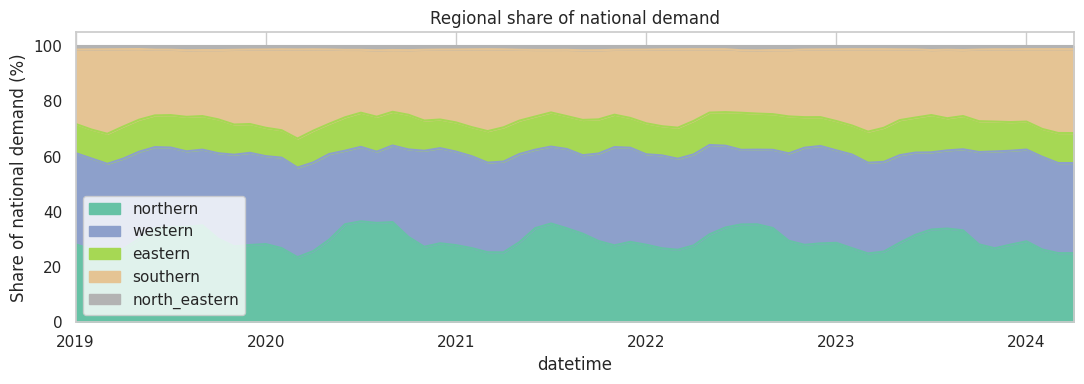

{'northern': 29.8, 'western': 31.5, 'eastern': 11.5, 'southern': 26.0, 'north_eastern': 1.3}


In [5]:
m = df.set_index("datetime")[REGIONS].resample("MS").mean()
share = m.div(m.sum(axis=1), axis=0) * 100
share.plot.area(figsize=(11, 4), colormap="Set2")
plt.ylabel("Share of national demand (%)"); plt.title("Regional share of national demand")
plt.tight_layout(); plt.savefig("results/figures/03_regional_shares.png", dpi=150); plt.show()
print(share.mean().round(1).to_dict())

In [6]:
apr = df[df["month"] == 4].groupby("year")["national"].mean()
covid = pd.DataFrame({"April mean demand (MW)": apr.round(0),
                      "Change vs April 2019 (%)": ((apr / apr.loc[2019] - 1) * 100).round(1)})
covid.to_csv("results/tables/covid_april_comparison.csv")
covid

,April mean demand (MW),Change vs April 2019 (%)
year,,
2019,154254.0,0.0
2020,116488.0,-24.5
2021,164737.0,6.8
2022,183461.0,18.9
2023,181327.0,17.6
2024,186426.0,20.9


Fixed threshold (95th pct of 2019-2022): 184885 MW
Share of hours above it, by year (%):
{2019: 0.0, 2020: 0.0, 2021: 2.1, 2022: 17.9, 2023: 46.7, 2024: 52.8}

Share of hours above ADAPTIVE threshold, by year (%):
{2019: 0.2, 2020: 4.7, 2021: 13.4, 2022: 11.8, 2023: 14.4, 2024: 7.5}


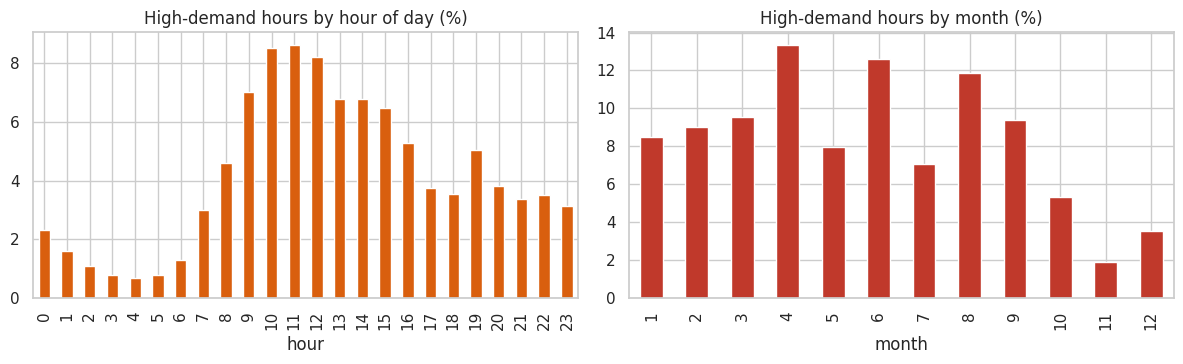

Peak hour of day (mean demand): 11


In [7]:
train = df[df["year"] <= 2022]
thr = train["national"].quantile(0.95)
df["is_high"] = (df["national"] > thr).astype(int)
print("Fixed threshold (95th pct of 2019-2022): %.0f MW" % thr)
print("Share of hours above it, by year (%):")
print((df.groupby("year")["is_high"].mean() * 100).round(1).to_dict())

# adaptive alternative: 95th percentile of the previous 365 days only (no look-ahead)
df["adaptive_thr"] = df["national"].rolling(24 * 365, min_periods=24 * 180).quantile(0.95).shift(1)
df["is_high_adaptive"] = (df["national"] > df["adaptive_thr"]).astype(int)
mask = df["adaptive_thr"].notna()
print("\nShare of hours above ADAPTIVE threshold, by year (%):")
print((df[mask].groupby("year")["is_high_adaptive"].mean() * 100).round(1).to_dict())

hi = df[df["is_high"] == 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
(hi["hour"].value_counts(normalize=True).sort_index() * 100).plot.bar(ax=axes[0], color="#d95f0e")
axes[0].set_title("High-demand hours by hour of day (%)")
(hi["month"].value_counts(normalize=True).sort_index() * 100).plot.bar(ax=axes[1], color="#c0392b")
axes[1].set_title("High-demand hours by month (%)")
plt.tight_layout(); plt.savefig("results/figures/03_peak_hours_months.png", dpi=150); plt.show()
print("Peak hour of day (mean demand):", int(df.groupby("hour")["national"].mean().idxmax()))

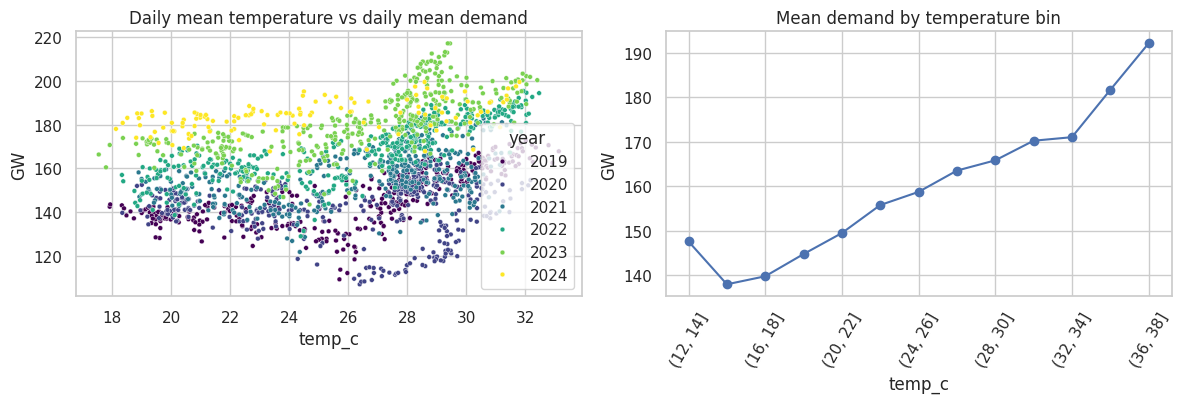

,Pearson (hourly),Spearman (hourly),Pearson (daily),Spearman (daily)
temp_c,0.421,0.400,0.320,0.353
rh_pct,-0.347,-0.340,-0.185,-0.175
dewpoint_c,0.122,0.112,0.138,0.129
wind_ms,0.213,0.220,0.147,0.158
solar_wm2,0.311,0.322,0.299,0.331
precip_mm,0.007,0.004,0.015,-0.013


In [8]:
WX = ["temp_c", "rh_pct", "dewpoint_c", "wind_ms", "solar_wm2", "precip_mm"]
daily = df.set_index("datetime")[["national"] + WX].resample("D").mean()

corr = pd.DataFrame({
    "Pearson (hourly)":  df[["national"] + WX].corr()["national"],
    "Spearman (hourly)": df[["national"] + WX].corr(method="spearman")["national"],
    "Pearson (daily)":   daily.corr()["national"],
    "Spearman (daily)":  daily.corr(method="spearman")["national"],
}).drop(index="national").round(3)
corr.to_csv("results/tables/demand_weather_correlations.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.scatterplot(data=daily.assign(year=daily.index.year), x="temp_c", y=daily["national"] / 1000,
                hue="year", palette="viridis", s=12, ax=axes[0])
axes[0].set_title("Daily mean temperature vs daily mean demand"); axes[0].set_ylabel("GW")
bins = pd.cut(df["temp_c"], bins=np.arange(10, 42, 2))
(df.groupby(bins, observed=True)["national"].mean() / 1000).plot(ax=axes[1], marker="o")
axes[1].set_title("Mean demand by temperature bin"); axes[1].set_ylabel("GW"); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig("results/figures/03_weather_relationships.png", dpi=150); plt.show()
corr

ADF test (daily mean demand): statistic=-2.204, p-value=0.2048
Skewness: 0.040 | Excess kurtosis: -0.357


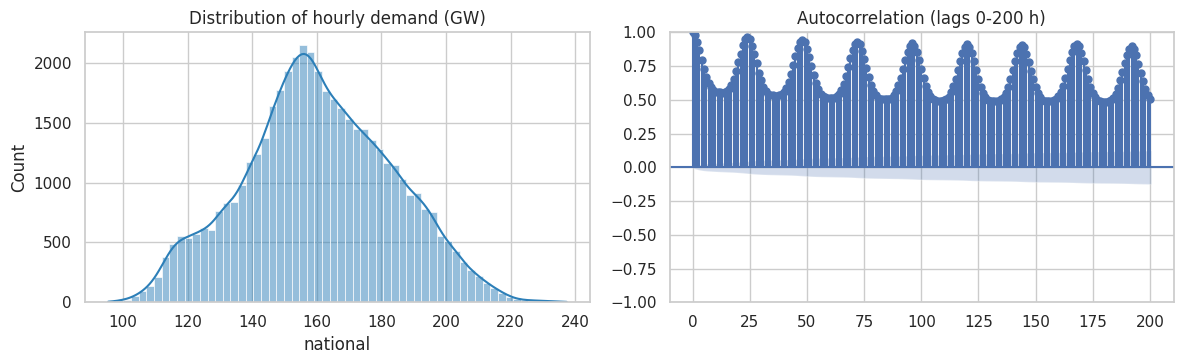

In [9]:
adf_stat, adf_p, *_ = adfuller(daily["national"].dropna(), autolag="AIC")
print("ADF test (daily mean demand): statistic=%.3f, p-value=%.4f" % (adf_stat, adf_p))
print("Skewness: %.3f | Excess kurtosis: %.3f" % (df["national"].skew(), df["national"].kurt()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df["national"] / 1000, bins=60, kde=True, ax=axes[0], color="#2c7fb8")
axes[0].set_title("Distribution of hourly demand (GW)")
plot_acf(df["national"], lags=200, ax=axes[1]); axes[1].set_title("Autocorrelation (lags 0-200 h)")
plt.tight_layout(); plt.savefig("results/figures/03_distribution_acf.png", dpi=150); plt.show()

## EDA observations
- Demand peaks on average at 11:00; there is a strong hour-of-day and seasonal (hour × month) structure.
- Mean annual demand grew from 146.8 GW (2019) to 180.8 GW (2023); 2020 dipped to 142.0 GW.
- April 2020 demand was 24.5% below April 2019 (COVID-19 lockdown).
- A fixed high-demand threshold (184,885 MW, 95th pct of 2019-2022) is exceeded 0% of hours in 2019-20
  but 46.7% in 2023 because of structural growth, so peak warnings need an adaptive threshold.
- Regional shares are stable: western 31.5%, northern 29.8%, southern 26.0%, eastern 11.5%, north-eastern 1.3%.
- Weather: <FILL IN from the correlation table and temperature-bin plot>.
- Stationarity: <FILL IN from the ADF result>.

In [10]:
!zip -qr /content/day2_eda_outputs.zip results
from google.colab import files
files.download("/content/day2_eda_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>